# Ablations: which factor groups matter most?

*Ahmed. Uses the clean table and folds from `02_data-analysis`.*

The 17 predictors come in 5 factor groups. Here we drop one group at a time, rerun gradient boosting with the settings picked in `ahmed_gradient_boosting.ipynb`, and see how much worse it gets on both tasks. The bigger the loss, the more that group adds that the other four can't make up for. Same 10 plausible values, same 5 school folds and same Rubin combining as the main notebook.

| Reads | Writes |
|---|---|
| `../data/clean/pisa6_clean.parquet` | `outputs/ahmed_ablations.csv` |
| `../data/clean/columns.json` | `outputs/figures/ahmed_ablations.png` |
| `../data/clean/folds.csv` | |
| `outputs/ahmed_hgb_params.json` | |
| `outputs/ahmed_hgb_results.csv` | |

# 1) Setup and data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import roc_auc_score, average_precision_score, root_mean_squared_error, r2_score

DATA = Path("../data")
OUT = Path("outputs")
FIGS = OUT / "figures"
df = pd.read_parquet(DATA / "clean/pisa6_clean.parquet")
roles = json.loads((DATA / "clean/columns.json").read_text(encoding="utf-8"))
folds = pd.read_csv(DATA / "clean/folds.csv")
df["fold"] = df["CNTSCHID"].map(folds.set_index("CNTSCHID")["fold"])
GROUPS = roles["feature_groups"]
FEATURES = [c for cols in GROUPS.values() for c in cols]
PVS = range(1, 11)
w = df["SENWT"] / df["SENWT"].mean()
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

best = json.loads((OUT / "ahmed_hgb_params.json").read_text(encoding="utf-8"))
saved = pd.read_csv(OUT / "ahmed_hgb_results.csv")

assert not any(c.startswith("PV") or "READ" in c or "SCIE" in c for c in FEATURES)
pd.Series({g: ", ".join(cols) for g, cols in GROUPS.items()}).rename("predictors").to_frame()

,predictors
family,"ESCS, PAREDINT, HISEI, HOMEPOS"
maths_attitudes,"ANXMAT, MATHEFF, MATHEF21"
classroom,"DISCLIM, TEACHSUP"
climate_resources,"BELONG, BULLIED, EDUSHORT, STAFFSHORT"
school_org,"MCLSIZE, STRATIO, SCHL_PRIVATE, SCHSIZE_log"


The settings come straight from the main notebook, so the only thing that changes between runs is which predictors the model sees. Dropping `family` removes ESCS together with its three parts. That matters here: ESCS is an exact mix of the other three, so if we dropped only some of them the rest would stand in for them.

# 1.1) The loop
The same loop as the main notebook, with the list of predictors as an extra argument. We only keep the two headline metrics per task: ROC-AUC and PR-AUC for below Level 2, RMSE and R² for the maths score.

In [2]:
def score(task, y, p, sw):
    if task == "classification":
        return {"roc_auc": roc_auc_score(y, p, sample_weight=sw),
                "pr_auc": average_precision_score(y, p, sample_weight=sw)}
    return {"rmse": root_mean_squared_error(y, p, sample_weight=sw),
            "r2": r2_score(y, p, sample_weight=sw)}


def target(task, pv):
    return df[f"BELOW_L2_PV{pv}"] if task == "classification" else df[f"PV{pv}MATH"]


def run(task, features, pvs):
    X = df[features]
    rows = []
    for pv in pvs:
        y = target(task, pv)
        for k in range(5):
            train, test = df["fold"] != k, df["fold"] == k
            if task == "classification":
                model = HistGradientBoostingClassifier(**best[task], random_state=0)
                model.fit(X[train], y[train], sample_weight=w[train] * compute_sample_weight("balanced", y[train]))
                p = model.predict_proba(X[test])[:, 1]
            else:
                model = HistGradientBoostingRegressor(**best[task], random_state=0)
                model.fit(X[train], y[train], sample_weight=w[train])
                p = model.predict(X[test])
            rows.append({"pv": pv, "fold": k, **score(task, y[test], p, w[test])})
    return pd.DataFrame(rows)


def rubin(res):
    per_pv = res.groupby("pv").mean().drop(columns="fold")
    within = res.groupby("pv").var().drop(columns="fold").mean() / 5
    between = per_pv.var()
    return pd.DataFrame({"score": per_pv.mean(), "se": np.sqrt(within + 1.1 * between)})

# 2) The full model again
The saved results only have the combined scores, not the score of each PV and fold. We rerun the full model here so every ablation can be compared with it on exactly the same PV and fold, and the standard error of the loss only carries the noise of the difference. With the same settings and `random_state=0` this is the same model as in the main notebook.

In [3]:
TASKS = ["classification", "regression"]
full = {task: run(task, FEATURES, PVS) for task in TASKS}

check = pd.concat([rubin(full[task]).assign(task=task) for task in TASKS]).rename_axis("metric").reset_index()
check = check.merge(saved[["task", "metric", "score"]], on=["task", "metric"], suffixes=("", "_saved"))
check.round(4)

,metric,score,se,task,score_saved
0,roc_auc,0.8186,0.0036,classification,0.8186
1,pr_auc,0.9034,0.0023,classification,0.9034
2,rmse,60.7497,0.3279,regression,60.7497
3,r2,0.4285,0.0117,regression,0.4285


> **Note:** the rerun gives the same scores as the saved results (`score` against `score_saved`), so the losses below are measured against the model from the main notebook. The `se` column is the usual Rubin one.

# 3) Dropping one group at a time
Five groups times two tasks, each on all plausible values and 5 folds. This is the slow part of the notebook.

In [4]:
ablated = {}
for group, cols in GROUPS.items():
    kept = [c for c in FEATURES if c not in cols]
    for task in TASKS:
        ablated[group, task] = run(task, kept, PVS)
len(ablated)

10

# 4) Loss per group
For each PV and fold we take the full model's score minus the ablated one (for RMSE the other way round, since lower is better), so a positive loss always means the model got worse without that group. Then we combine these differences with the same Rubin step as the scores.

In [5]:
rows = []
for (group, task), res in ablated.items():
    diff = full[task].copy()
    for metric in diff.columns.drop(["pv", "fold"]):
        sign = -1 if metric == "rmse" else 1
        diff[metric] = sign * (full[task][metric] - res[metric])
    loss = rubin(diff).rename(columns={"score": "loss"})
    loss["full_score"] = rubin(full[task])["score"]
    loss["ablated_score"] = rubin(res)["score"]
    rows.append(loss.rename_axis("metric").reset_index().assign(task=task, dropped_group=group))

ablations = pd.concat(rows).assign(model="gradient_boosting")
ablations = ablations[["model", "task", "dropped_group", "metric", "full_score", "ablated_score", "loss", "se"]]
ablations = ablations.sort_values(["task", "metric", "loss"], ascending=[True, True, False])
ablations.to_csv(OUT / "ahmed_ablations.csv", index=False)
loss_table = ablations.pivot_table(index="dropped_group", columns="metric", values="loss").sort_values("roc_auc", ascending=False)
loss_table.round(4)

metric,pr_auc,r2,rmse,roc_auc
dropped_group,,,,
family,0.0133,0.0384,2.0123,0.0194
maths_attitudes,0.0095,0.0574,2.9801,0.0179
school_org,0.0081,0.0404,2.1250,0.0136
climate_resources,0.0057,0.0189,1.0008,0.0059
classroom,0.0019,0.0095,0.5061,0.0033


In [6]:
ablations.pivot_table(index="dropped_group", columns="metric", values="se").loc[loss_table.index].round(4)

metric,pr_auc,r2,rmse,roc_auc
dropped_group,,,,
family,0.0017,0.0020,0.1115,0.0014
maths_attitudes,0.0010,0.0021,0.1195,0.0014
school_org,0.0013,0.0046,0.2621,0.0017
climate_resources,0.0009,0.0019,0.1001,0.0011
classroom,0.0006,0.0015,0.0791,0.0006


> **Note:** every group costs something, but not the same amount. For below Level 2, dropping family (ROC-AUC down 0.019 ± 0.001) or maths attitudes (0.018 ± 0.001) costs most, and the two are too close to rank. School organisation is a bit lower (0.014 ± 0.002). It is clearly below family (the gap is about 2.6 se) but only about 2 se below maths attitudes, so we don't rank those two. Then come climate and resources (0.006 ± 0.001) and classroom (0.003 ± 0.001), which add little. For the maths score, maths attitudes costs most (R² down 0.057 ± 0.002, RMSE up 3.0 points), then school organisation (0.040 ± 0.005) and family (0.038 ± 0.002), which are within the error bars of each other, so we don't rank those two. Classroom costs least: 0.010 ± 0.001 of R² and 0.5 points of RMSE.

# 5) Figure
One panel per task: the loss in ROC-AUC for below Level 2 and the loss in R² for the maths score, with 95% intervals (1.96 se). We use R² rather than RMSE on the right so both panels read the same way and the numbers sit next to the EDA's linear R².

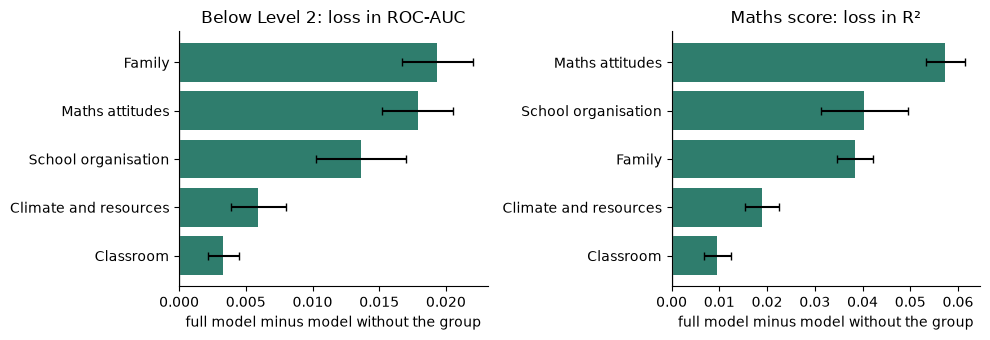

In [7]:
TITLES = {"roc_auc": "Below Level 2: loss in ROC-AUC", "r2": "Maths score: loss in R²"}
NAMES = {"family": "Family", "maths_attitudes": "Maths attitudes", "school_org": "School organisation",
         "climate_resources": "Climate and resources", "classroom": "Classroom"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (task, metric) in zip(axes, [("classification", "roc_auc"), ("regression", "r2")]):
    d = ablations[(ablations["task"] == task) & (ablations["metric"] == metric)].sort_values("loss")
    ax.barh(d["dropped_group"].map(NAMES), d["loss"], xerr=1.96 * d["se"], color="#2F7D6D", capsize=3)
    ax.axvline(0, color="grey", lw=1)
    ax.set_title(TITLES[metric])
    ax.set_xlabel("full model minus model without the group")
fig.tight_layout()
fig.savefig(FIGS / "ahmed_ablations.png", bbox_inches="tight", dpi=150)
plt.show()

> **Note:** on the right, maths attitudes clearly stands out and classroom is last. On the left the top three bars overlap, and the numbers in section 4 only clearly separate family from school organisation (maths attitudes and school organisation are about 2 se apart). Each bar is that group's own 95% interval, not a test between two groups, so overlapping bars don't settle the order by themselves.

# 6) Compared with the EDA

The linear check in `02_eda` (weighted R² for each group, pooled) found that school organisation lost the most when dropped (0.070), then maths attitudes (0.043) and family (0.032), with climate and resources (0.012) and classroom (0.002) well behind. Gradient boosting agrees at the bottom: classroom is the least useful group for both tasks, with climate and resources next. At the top it doesn't fully agree. School organisation is still one of the three big groups, but here maths attitudes costs more than it for the maths score, and for below Level 2 the two are too close to rank. Family costs more than school organisation for below Level 2 and about the same for the maths score. A likely reason is that gradient boosting can fit curves and interactions in the student-level groups, which a linear model can't. The two checks also measure different things: the EDA one is a linear fit on the whole table, ours is scored on schools the model never saw.

# 7) Summary

- Gradient boosting with the main notebook's settings, rerun with each of the 5 factor groups dropped, on all PVs and the 5 school folds. The loss is paired with the full model on each PV and fold and combined with Rubin's rules. Everything is in `outputs/ahmed_ablations.csv` and the figure in section 5.
- The groups that matter most are family, maths attitudes and school organisation. For below Level 2, family and maths attitudes are joint top (ROC-AUC down 0.019 and 0.018, both ± 0.001). For the maths score, maths attitudes is clearly first (R² down 0.057 ± 0.002, RMSE up 3.0 points), and family and school organisation are too close to rank.
- Classroom matters least for both tasks (ROC-AUC down 0.003 ± 0.001, R² down 0.010 ± 0.001), which matches the EDA. School organisation, the strongest group in the linear EDA check, is in the top three here but not first.

Next: `../04_neural-networks/ahmed_mlp.ipynb` (MLP compared with gradient boosting).